# What is the "direction-balanced sample"? (explainer for v2.1.5 / v3.1.5)

k-means is fitted on a **sample** of 500,000 of the ~15 million particles. This
notebook shows, step by step and with plots, how v2.1.5 / v3.1.5 choose that
sample, why, and what it changes.

**In one sentence:** every particle gets a *direction* (from where it crosses
2.5N to where it is at 2000 km, or where its track ends); the compass is cut
into 24 slices of 15°; and the 500,000 particles are drawn so that **every
slice contributes about the same number**, instead of in proportion to how
crowded it is. Only the fit sample is balanced - afterwards all particles are
labelled, so every share (%) that is reported is still the real one.

**Contents**
1. Why plain random sampling misses rare routes
2. One particle: its direction and its 15° sector
3. All 24 sectors on the map
4. How many particles per sector - before and after balancing
5. What k-means does with each sample
6. Why the reported shares are still the real ones
7. Background and references

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # project root: config.py, pipeline.py
import numpy as np
import pandas as pd
import config as C
import pipeline as P
print("project root:", C.PROJECT_ROOT)
print(f"crossing: {C.LAT_CROSS} N | radii (km): {C.RADII_KM}")

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cartopy.feature as cfeature
from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import StandardScaler

SECTOR_DEG = 15                  # width of one direction slice
N_SUB = 500_000                  # particles in the fit sample
SEED = 42
R_OUT = C.RADII_KM[-1]           # outermost radius (2000 km)
RADIUS_WEIGHTS = {200: 0.027, 500: 0.166, 1000: 0.663, 1500: 1.492, 2000: 2.653}   # as in v3
K_DEMO = 400

_coast = []
for geom in cfeature.COASTLINE.with_scale("110m").geometries():
    for line in getattr(geom, "geoms", [geom]):
        _coast.append((np.asarray(line.xy[0]), np.asarray(line.xy[1])))
def draw_coast(ax, lon=(-72, -25), lat=(-3, 22)):
    for x, y in _coast:
        ax.plot(x, y, "-", color="0.7", lw=.5, zorder=0)
    ax.set_xlim(*lon); ax.set_ylim(*lat); ax.set_aspect("equal")
    ax.axhline(C.LAT_CROSS, color="k", ls="--", lw=.6)

def compass(b):                  # bearing (deg, 0 = N, 90 = E, -90 = W) -> text
    names = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE", "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
    return names[int(np.round((b % 360) / 22.5)) % 16]

project root: /work/bk1450/b383184/Amazon/Mercator/notebooks/run_2/kmeans_radius
crossing: 2.5 N | radii (km): [200, 500, 1000, 1500, 2000]


## 1. Why plain random sampling misses rare routes

k-means puts its cluster centres **where the particles are dense**. With many
clusters, the density of centres follows the density of the data (raised to a
power a bit below 1; quantization theory, Gersho 1979). So if 86% of the
particles go one way and 3% another, the 3% get only a handful of centres -
however different their route is. Balancing the *sample* gives the rare routes
enough particles to get their own clusters.

## 2. One particle: its direction and its 15° sector

The **direction** of a particle = the compass direction from its crossing
point on 2.5N to its *outer point*: where it first gets 2000 km away, or - for
a `partial` particle whose track ends earlier - its last position. (0° = north,
90° = east, -90° = west.) The compass is cut into 24 slices of 15°; each
particle belongs to exactly one slice.

15,068,653 particles (complete + partial)


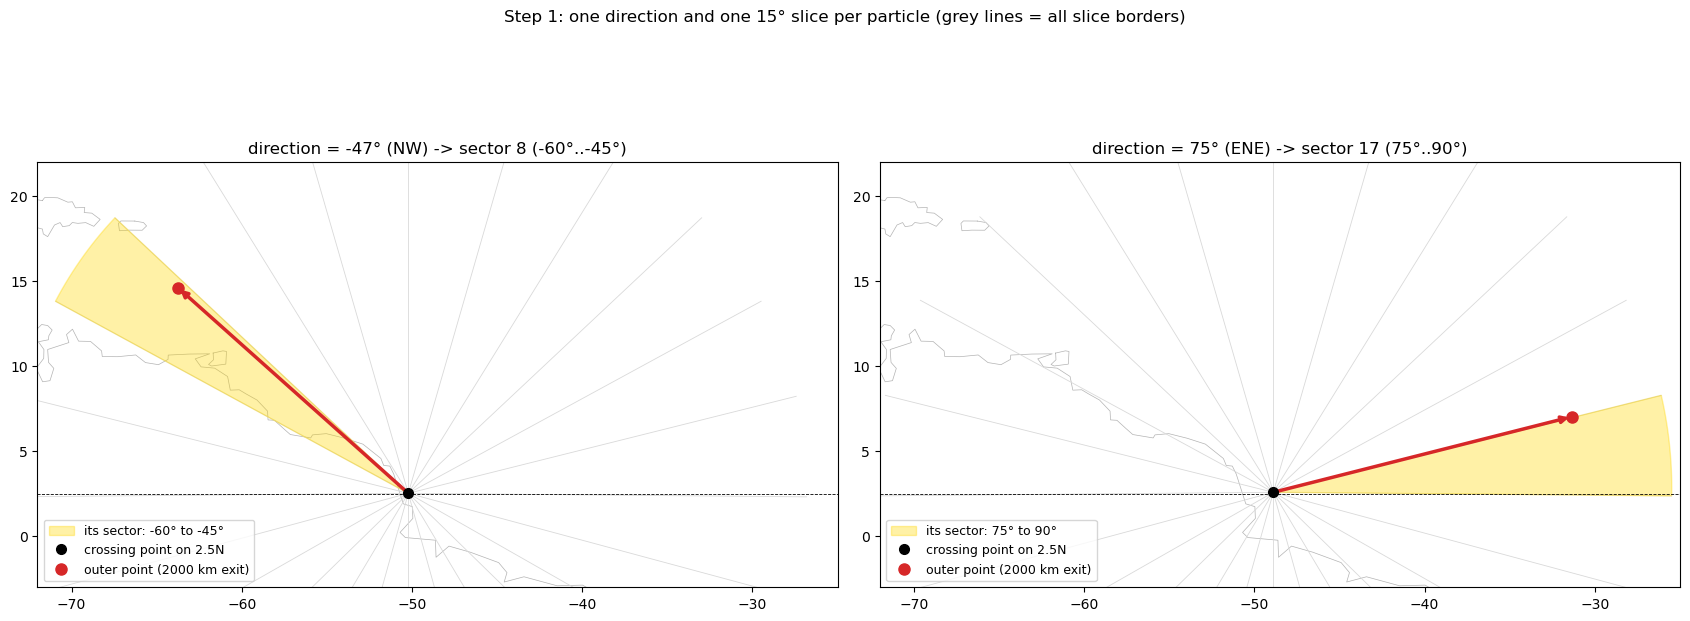

In [2]:
f = pd.read_parquet(C.FEATURES_FILE, columns=["status", "cross_lat", "cross_lon", "trajectory_id"]
                    + P.feature_columns())
fit = f[f.status.isin(["complete", "partial"])].reset_index(drop=True); del f
bearing = P.bearing_deg(fit.cross_lat, fit.cross_lon, fit[P.lat_col(R_OUT)], fit[P.lon_col(R_OUT)])
n_sec = 360 // SECTOR_DEG
sector = np.clip(np.floor((bearing + 180) / SECTOR_DEG).astype(int), 0, n_sec - 1)
edges = -180 + SECTOR_DEG * np.arange(n_sec + 1)                  # sector k covers edges[k] .. edges[k+1]
print(f"{len(fit):,} particles (complete + partial)")

# two example particles: one going north-west (common), one going east (rare)
ex = [int(np.where((bearing > -50) & (bearing < -40))[0][0]), int(np.where((bearing > 70) & (bearing < 80))[0][0])]
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, i in zip(axes, ex):
    draw_coast(ax)
    la0, lo0 = fit.cross_lat[i], fit.cross_lon[i]
    la1, lo1 = fit[P.lat_col(R_OUT)][i], fit[P.lon_col(R_OUT)][i]
    # the 24 slices as thin lines from the crossing point, the particle's slice shaded
    for e in edges[:-1]:
        cla, clo = P.circle_latlon(la0, lo0, 2600, n=361)
        k = int(round((e % 360)))
        ax.plot([lo0, clo[k]], [la0, cla[k]], "-", color="0.85", lw=.6, zorder=1)
    k0 = sector[i]
    angs = np.arange(int(edges[k0]), int(edges[k0 + 1]) + 1) % 360
    cla, clo = P.circle_latlon(la0, lo0, 2600, n=361)
    ax.fill(np.r_[lo0, clo[angs], lo0], np.r_[la0, cla[angs], la0], color="gold", alpha=.35, zorder=1,
            label=f"its sector: {edges[k0]:.0f}° to {edges[k0+1]:.0f}°")
    ax.annotate("", xy=(lo1, la1), xytext=(lo0, la0),
                arrowprops=dict(arrowstyle="-|>", lw=2.5, color="tab:red"), zorder=3)
    ax.plot(lo0, la0, "ko", ms=7, zorder=4, label="crossing point on 2.5N")
    ax.plot(lo1, la1, "o", color="tab:red", ms=8, zorder=4,
            label=f"outer point ({'2000 km exit' if fit.status[i] == 'complete' else 'last position'})")
    ax.set_title(f"direction = {bearing[i]:.0f}° ({compass(bearing[i])}) -> sector {k0} "
                 f"({edges[k0]:.0f}°..{edges[k0+1]:.0f}°)")
    ax.legend(loc="lower left", fontsize=9)
fig.suptitle("Step 1: one direction and one 15° slice per particle (grey lines = all slice borders)", y=1.0)
fig.tight_layout(); plt.show()

## 3. All 24 sectors on the map

The slices drawn from the mean crossing point, with the outer points of 30,000
random particles coloured by their slice. Most points fall in a few slices to
the north-west; the eastern slices hold very few particles.

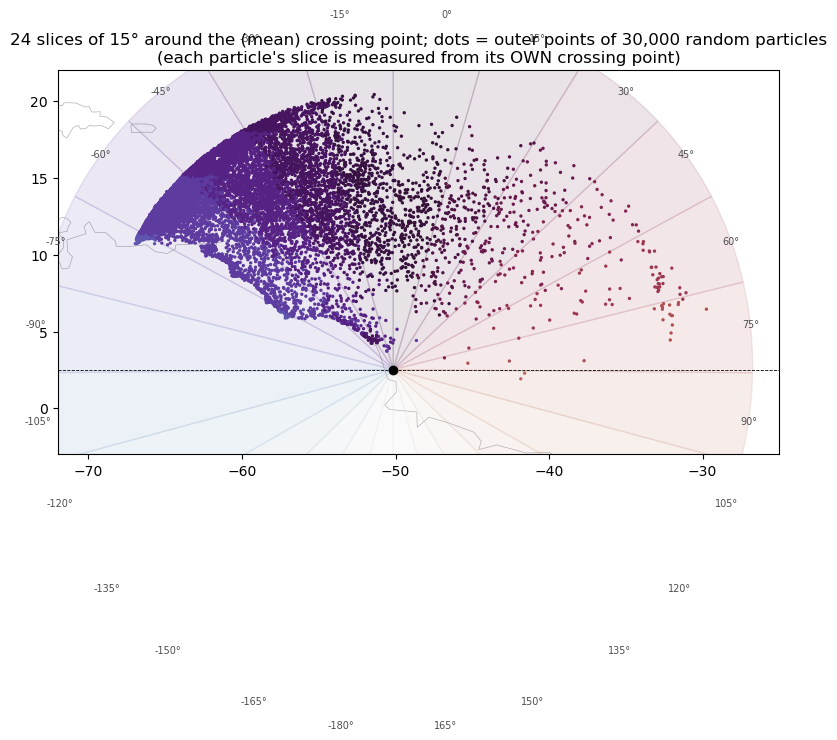

In [3]:
rng = np.random.default_rng(0)
show = rng.choice(len(fit), 30_000, replace=False)
la0, lo0 = fit.cross_lat.mean(), fit.cross_lon.mean()
cmap = plt.get_cmap("twilight", n_sec)
fig, ax = plt.subplots(figsize=(13, 8))
draw_coast(ax)
cla, clo = P.circle_latlon(la0, lo0, 2600, n=361)
for k in range(n_sec):
    angs = np.arange(int(edges[k]), int(edges[k + 1]) + 1) % 360
    ax.fill(np.r_[lo0, clo[angs], lo0], np.r_[la0, cla[angs], la0], color=cmap(k), alpha=.12, zorder=1)
    mid = int(round((edges[k] + SECTOR_DEG / 2) % 360))
    ax.text(clo[mid], cla[mid], f"{edges[k]:.0f}°", fontsize=7, ha="center", va="center", color="0.3")
ax.scatter(fit[P.lon_col(R_OUT)].to_numpy()[show], fit[P.lat_col(R_OUT)].to_numpy()[show],
           c=[cmap(k) for k in sector[show]], s=2, zorder=2)
ax.plot(lo0, la0, "ko", ms=6, zorder=3)
ax.set_title("24 slices of 15° around the (mean) crossing point; dots = outer points of 30,000 random particles\n"
             "(each particle's slice is measured from its OWN crossing point)")
fig.tight_layout(); plt.show()

## 4. How many particles per sector - before and after balancing

**Sampling weight.** Each particle gets a chance to be drawn proportional to
`n_sector ** (alpha - 1)`, where `n_sector` = how many particles share its
slice:

* `alpha = 1`: every particle the same chance -> the sample has the same mix as
  the data (as in 1.5);
* `alpha = 0`: chance ∝ 1 / n_sector -> every non-empty slice contributes about
  equally (as in v2 / v3);
* `alpha = 0.5`: in between - chance ∝ 1 / sqrt(n_sector); rare slices are
  boosted, but crowded slices still give more than rare ones.

v2.1.5 / v3.1.5 use **alpha = 0**; alpha = 0.5 is the gentler option.

Slices with very few particles cannot give more than they have; they are drawn
almost completely, so the "equal" share is approximate.

                   particles  % of all particles  % of fit sample, alpha=1  % of fit sample, alpha=0.5  % of fit sample, alpha=0
slice                                                                                                                           
-165..-150° (SSW)          1                0.00                      0.00                        0.00                      0.00
-150..-135° (SW)           1                0.00                      0.00                        0.00                      0.00
-90..-75° (W)              1                0.00                      0.00                        0.00                      0.00
-75..-60° (WNW)       171888                1.14                      1.15                        4.78                     10.60
-60..-45° (NW)       9278146               61.57                     61.68                       37.38                     12.56
-45..-30° (NW)       3960236               26.28                     26.20                       

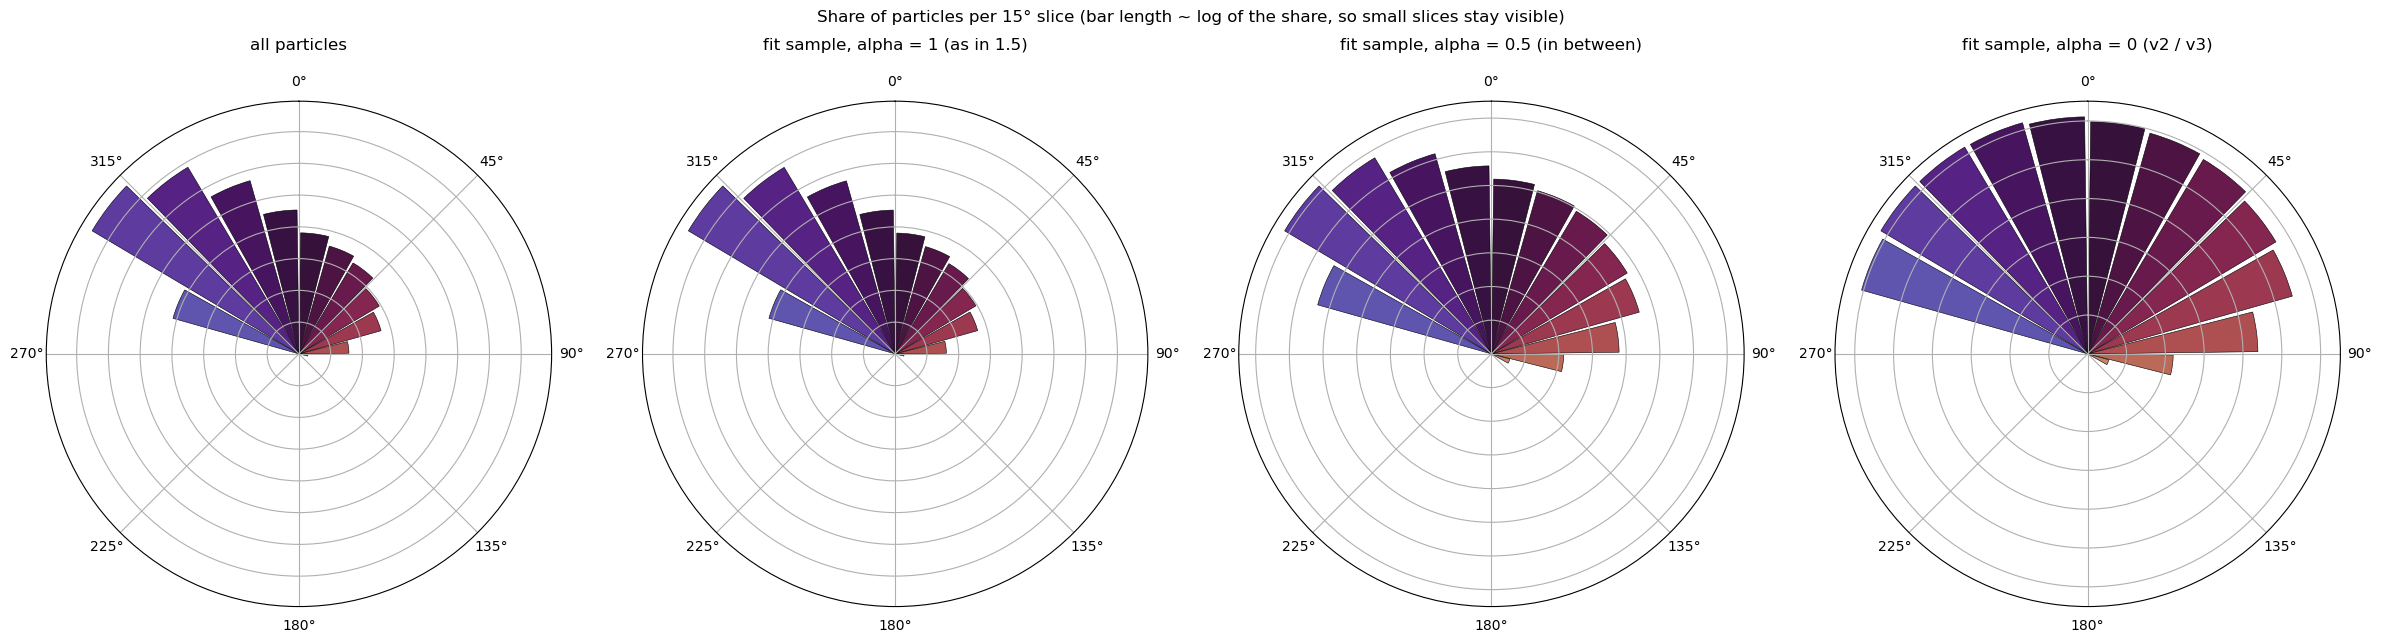

alpha=1: share of the fit sample with an eastward direction =   2.4%  (all particles: 2.4%)
alpha=0.5: share of the fit sample with an eastward direction =  15.1%  (all particles: 2.4%)
alpha=0: share of the fit sample with an eastward direction =  40.7%  (all particles: 2.4%)


In [4]:
n_sector = np.bincount(sector, minlength=n_sec)
def balanced_sample(alpha, seed=SEED, n=N_SUB):
    w = n_sector[sector].astype(float) ** (alpha - 1.0)
    return np.random.default_rng(seed).choice(len(fit), size=min(n, len(fit)), replace=False, p=w / w.sum())

samples = {a: balanced_sample(a) for a in (1.0, 0.5, 0.0)}
tab = pd.DataFrame({"slice": [f"{edges[k]:+.0f}..{edges[k+1]:+.0f}° ({compass(edges[k] + 7.5)})" for k in range(n_sec)],
                    "particles": n_sector,
                    "% of all particles": 100 * n_sector / n_sector.sum()})
for a, idx in samples.items():
    tab[f"% of fit sample, alpha={a:g}"] = 100 * np.bincount(sector[idx], minlength=n_sec) / len(idx)
tab = tab[tab.particles > 0].set_index("slice")
print(tab.round(2).to_string())

centers = np.deg2rad(edges[:-1] + SECTOR_DEG / 2)
fig, axes = plt.subplots(1, 4, figsize=(24, 6), subplot_kw={"projection": "polar"})
for ax, (a, title) in zip(axes, [(None, "all particles"), (1.0, "fit sample, alpha = 1 (as in 1.5)"),
                                 (0.5, "fit sample, alpha = 0.5 (in between)"),
                                 (0.0, "fit sample, alpha = 0 (v2 / v3)")]):
    pct = tab["% of all particles"] if a is None else tab[f"% of fit sample, alpha={a:g}"]
    full = np.zeros(n_sec); full[n_sector > 0] = pct.to_numpy()
    ax.bar(centers, np.log10(1 + 100 * full), width=np.deg2rad(SECTOR_DEG) * .9,
           color=[cmap(k) for k in range(n_sec)], edgecolor="k", lw=.4)
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)       # compass: N up, clockwise
    ax.set_yticklabels([])
    ax.set_title(title, pad=18)
fig.suptitle("Share of particles per 15° slice (bar length ~ log of the share, so small slices stay visible)", y=1.02)
fig.tight_layout(); plt.show()

east = bearing > 0
for a, idx in samples.items():
    print(f"alpha={a:g}: share of the fit sample with an eastward direction = {100 * east[idx].mean():5.1f}%  "
          f"(all particles: {100 * east.mean():.1f}%)")

### The sampling rule as a formula

**Notation.** $N$ = sample size (500,000); $s(i)$ = direction slice of particle
$i$; $n_s$ = number of particles in slice $s$; $\alpha$ = `BALANCE_ALPHA`.

**1. Weight of each particle**

$$w_i = n_{s(i)}^{\,\alpha - 1}$$

* $\alpha = 1$: $w_i = 1$ - every particle equal (plain random sample);
* $\alpha = 0$: $w_i = 1/n_{s(i)}$ - the weights of one slice add up to
  $n_s \cdot 1/n_s = 1$, so **every slice has the same total weight**, whatever
  its size;
* $\alpha = 0.5$: $w_i = 1/\sqrt{n_{s(i)}}$ - slice total $= \sqrt{n_s}$.

**2. Drawing without replacement, one particle at a time** (successive
sampling with unequal probabilities). If $R$ is the set of particles not drawn
yet, the next particle is $i$ with probability

$$P(\text{next} = i) = \frac{w_i}{\sum_{j \in R} w_j}.$$

**3. The "pull" of a slice.** With $\alpha = 0$ and $r_s$ particles of slice
$s$ still undrawn, the chance that the next particle comes from slice $s$ is

$$P(\text{next from } s) = \frac{r_s / n_s}{\sum_t r_t / n_t},$$

i.e. each slice pulls with the **fraction of its particles that is still
undrawn**. All slices start with pull 1; a small slice loses its pull as it is
emptied; a huge slice (millions) hardly empties and keeps pulling at ~1.

**4. How many particles each slice gives (prediction).** Treating the draws
as continuous, slice $s$ ends with about

$$m_s \approx n_s\left(1 - e^{-\tau / n_s}\right), \qquad \text{with } \tau \text{ chosen so that } \sum_s m_s = N.$$

* small slice ($n_s \ll \tau$): $m_s \approx n_s$ - **all its particles are taken**;
* huge slice ($n_s \gg \tau$): $m_s \approx \tau$ - every large slice gives about the
  **same** number, $\tau$;
* in between, the slice is partly emptied.

*Toy check* (3 slices of 1,000,000 / 10,000 / 100 particles, $N$ = 30,000): the
formula gives $\tau$ = 21,312 and 21,087 / 8,813 / 100; drawing with the
notebook's code gives 21,033-21,075 / 8,825-8,867 / 100. The cell below does
the same check on the real slices.

**How to say it in one sentence:** *"k-means was fitted on a 500,000-particle
subsample drawn without replacement with probability inversely proportional to
the number of particles in the particle's 15° outer-direction sector
($\alpha = 0$), so that every direction sector carries equal weight in the fit;
sectors with fewer particles than their share contribute all of them. All
reported proportions are computed by assigning every particle to its nearest
centroid, i.e. on the full, unweighted population."*

In [5]:
# prediction (formula 4) vs what the sampling actually drew, alpha = 0
from scipy.optimize import brentq
ns = n_sector[n_sector > 0].astype(float)
tau = brentq(lambda t: (ns * (1 - np.exp(-t / ns))).sum() - N_SUB, 1, 1e9)
m_pred = ns * (1 - np.exp(-tau / ns))
m_real = np.bincount(sector[samples[0.0]], minlength=n_sec)[n_sector > 0]
chk = pd.DataFrame({"particles n_s": ns.astype(int), "predicted m_s": m_pred.round(0).astype(int),
                    "drawn": m_real, "taken (% of slice)": (100 * m_real / ns).round(1)},
                   index=tab.index)
print(f"tau = {tau:,.0f} -> every large slice gives about tau particles")
chk

tau = 63,135 -> every large slice gives about tau particles


,particles n_s,predicted m_s,drawn,taken (% of slice)
slice,,,,
-165..-150° (SSW),1,1,1,100.0
-150..-135° (SW),1,1,1,100.0
-90..-75° (W),1,1,1,100.0
-75..-60° (WNW),171888,52838,53001,30.8
-60..-45° (NW),9278146,62921,62799,0.7
-45..-30° (NW),3960236,62634,62693,1.6
-30..-15° (NNW),1024693,61229,61818,6.0
-15..+0° (N),276417,56444,56369,20.4
+0..+15° (N),119790,49072,48818,40.8


### The samples on the map

**Note:** each panel below draws only the **first 30,000** particles of its
500,000-particle sample, so the dots stay readable - every panel has exactly
30,000 dots. With alpha = 0 they are *spread* over many more directions instead
of piled on top of each other in the north-west, which makes the panel look
fuller. The density maps after it use **all 500,000** particles of each sample.

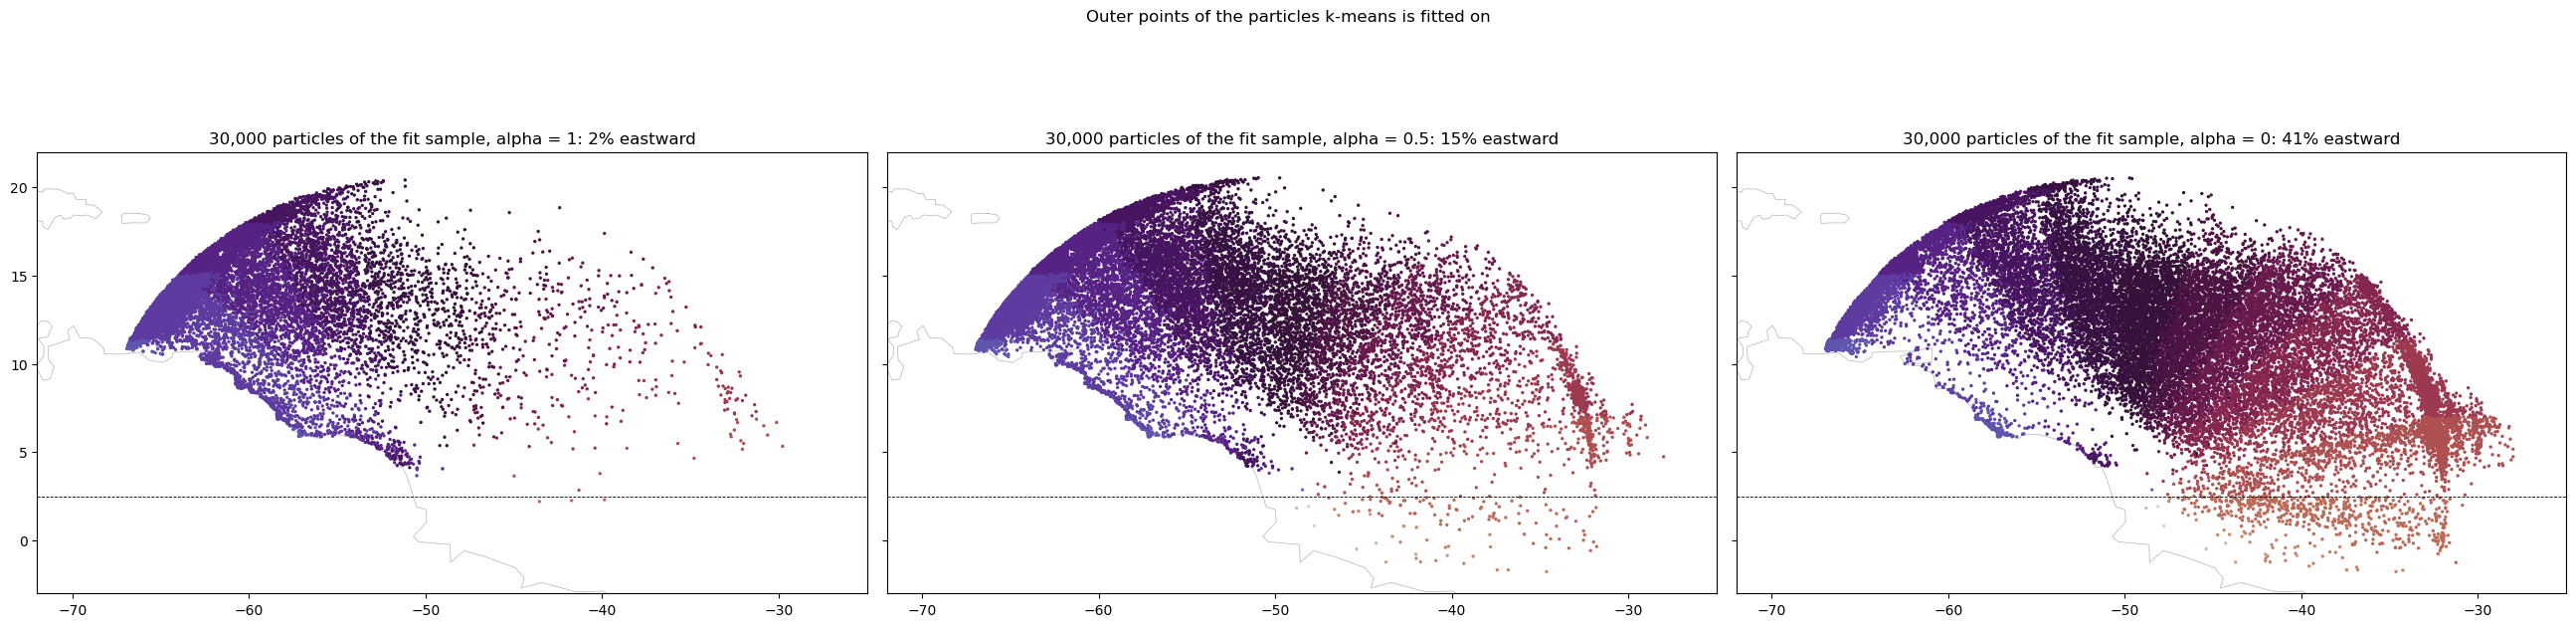

In [6]:
# the same samples on the map: what k-means 'sees' (30,000 dots per panel, for readability)
fig, axes = plt.subplots(1, 3, figsize=(26, 7), sharex=True, sharey=True)
for ax, a in zip(axes, (1.0, 0.5, 0.0)):
    idx = samples[a][:30_000]
    draw_coast(ax)
    ax.scatter(fit[P.lon_col(R_OUT)].to_numpy()[idx], fit[P.lat_col(R_OUT)].to_numpy()[idx],
               c=[cmap(k) for k in sector[idx]], s=2)
    ax.set_title(f"30,000 particles of the fit sample, alpha = {a:g}: "
                 f"{100 * east[samples[a]].mean():.0f}% eastward")
fig.suptitle("Outer points of the particles k-means is fitted on", y=1.0)
fig.tight_layout(); plt.show()

### Density of the whole fit sample (all 500,000 particles)

Number of sample particles whose outer point falls in each 0.5° cell (log
colour scale, same scale in the three panels). Total in every panel = 500,000.
With alpha = 1 the north-west cells hold tens of thousands of particles each
and the east is almost empty; with alpha = 0 fewer particles come from the
north-west and the eastern cells fill up - with the **same total**.

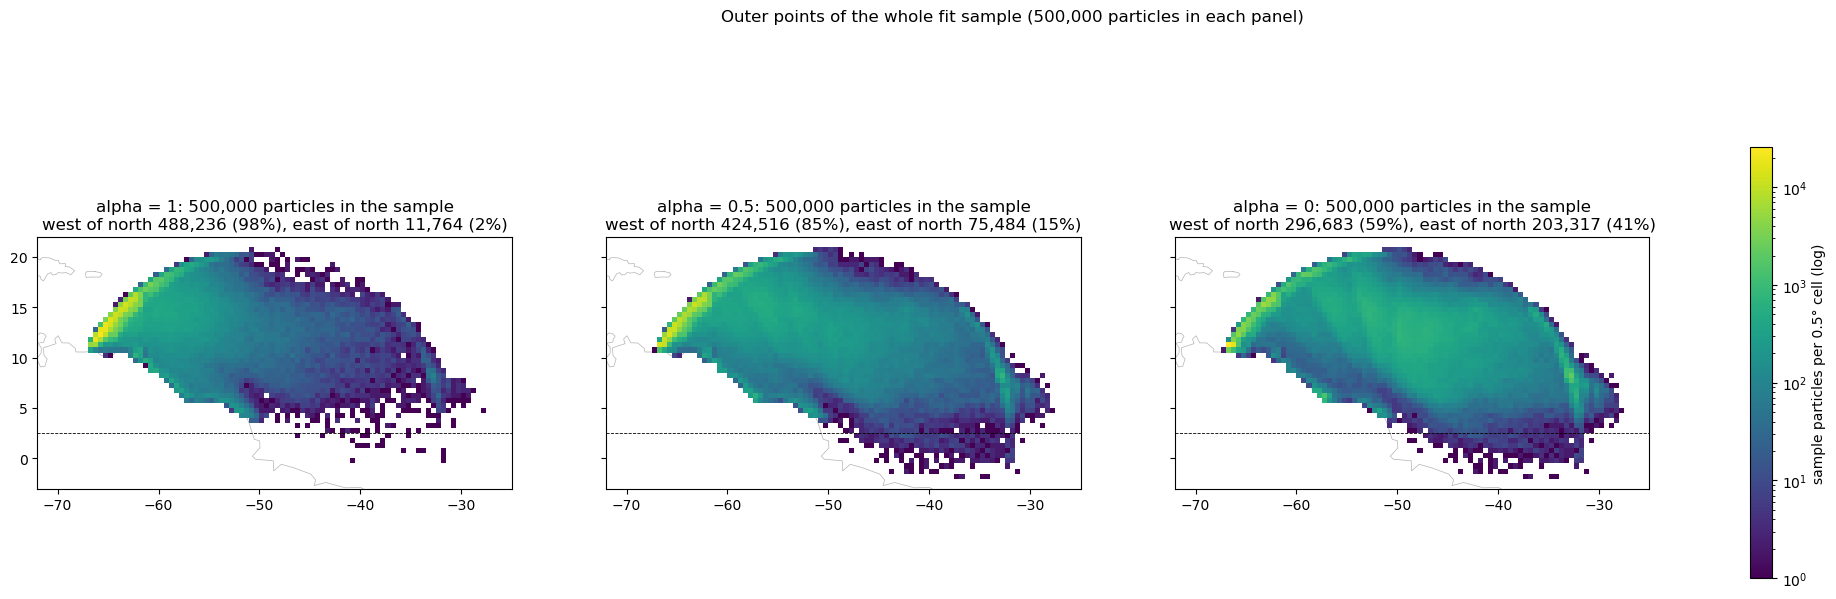

In [7]:
from matplotlib.colors import LogNorm
lon_b = np.arange(-72, -25 + 0.5, 0.5); lat_b = np.arange(-3, 22 + 0.5, 0.5)
lon_out = fit[P.lon_col(R_OUT)].to_numpy(); lat_out = fit[P.lat_col(R_OUT)].to_numpy()
H = {a: np.histogram2d(lon_out[idx], lat_out[idx], bins=[lon_b, lat_b])[0].T for a, idx in samples.items()}
vmax = max(h.max() for h in H.values())
fig, axes = plt.subplots(1, 3, figsize=(26, 7), sharex=True, sharey=True)
for ax, a in zip(axes, (1.0, 0.5, 0.0)):
    draw_coast(ax)
    pcm = ax.pcolormesh(lon_b, lat_b, np.where(H[a] > 0, H[a], np.nan), norm=LogNorm(1, vmax),
                        cmap="viridis", shading="flat", zorder=1)
    idx = samples[a]
    nw = (bearing[idx] < 0).sum(); ea = (bearing[idx] > 0).sum()
    ax.set_title(f"alpha = {a:g}: {len(idx):,} particles in the sample\n"
                 f"west of north {nw:,} ({100 * nw / len(idx):.0f}%), east of north {ea:,} ({100 * ea / len(idx):.0f}%)")
fig.colorbar(pcm, ax=axes, shrink=.8, label="sample particles per 0.5° cell (log)")
fig.suptitle("Outer points of the whole fit sample (500,000 particles in each panel)", y=1.0)
plt.show()

## 5. What k-means does with each sample

The same fit as v3 (radius weights ~ radius², K = 400) on the three samples
(alpha = 1, 0.5, 0). Each
centroid is given the direction of its own centroid track (crossing -> outer
point). Left: how many of the 400 centroids point into each slice; right: the
centroid tracks.

alpha=1: 40 of 400 centroids point east


alpha=0.5: 130 of 400 centroids point east


alpha=0: 216 of 400 centroids point east


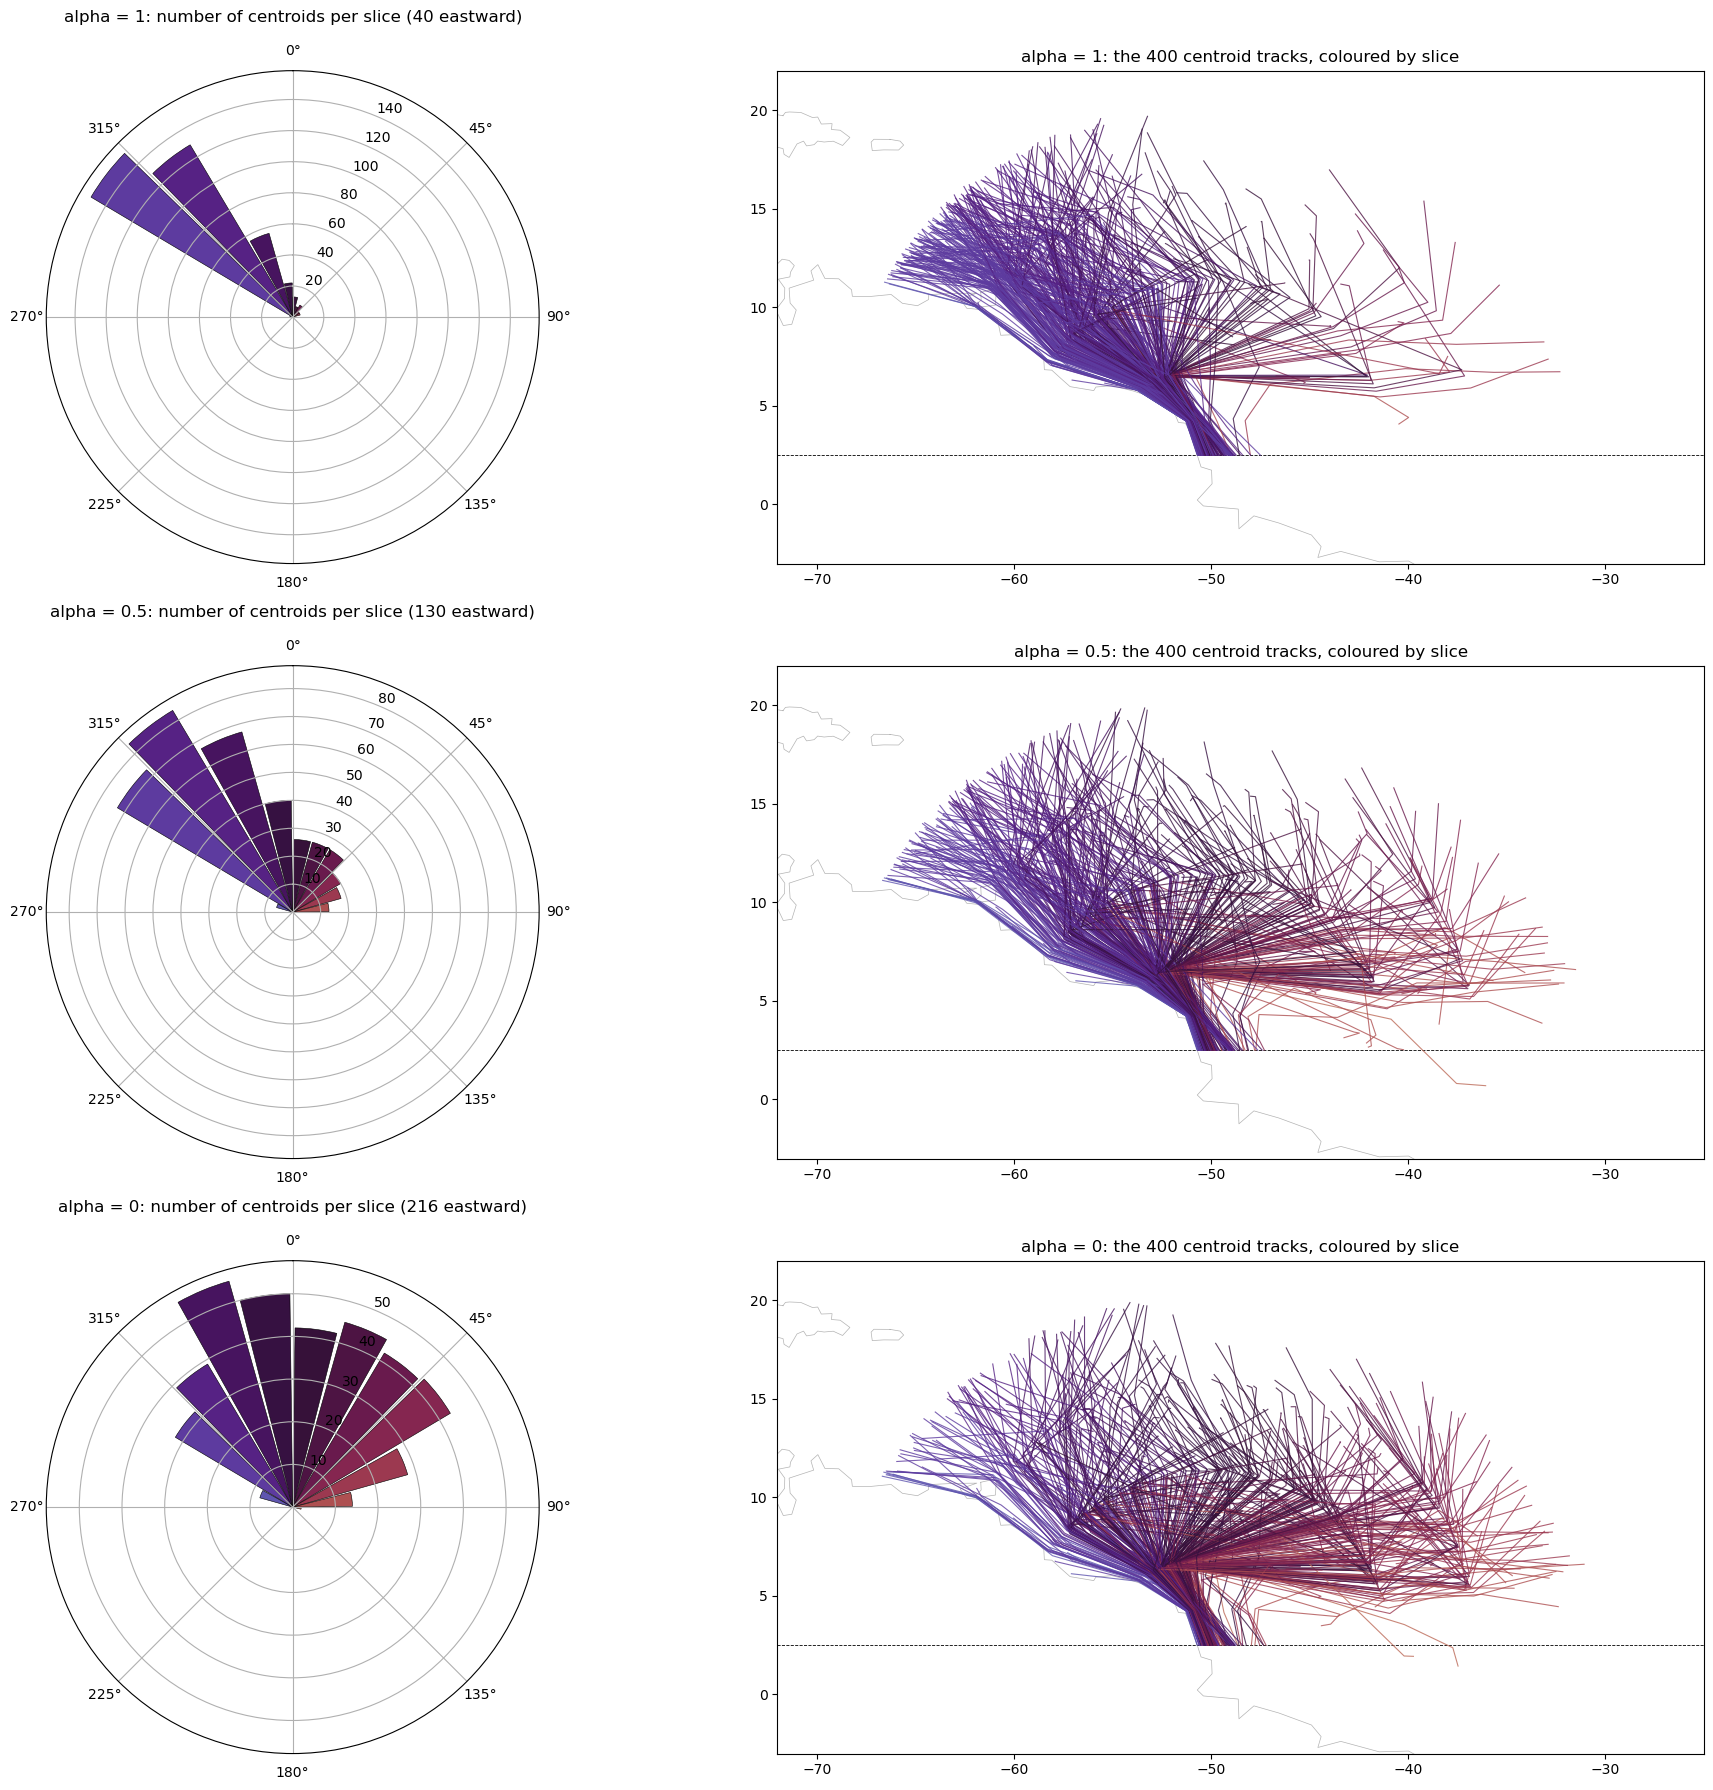

In [8]:
X_all = P.build_feature_matrix(fit)
W = P.feature_weight_vector(RADIUS_WEIGHTS)
start_all = fit.cross_lon.to_numpy()
fits = {}
for a in (1.0, 0.5, 0.0):
    idx = samples[a]
    sc = StandardScaler().fit(X_all[idx])
    km = MiniBatchKMeans(n_clusters=K_DEMO, random_state=SEED, batch_size=10000, n_init=10,
                         max_iter=300).fit(sc.transform(X_all[idx]) * W)
    cent = pd.DataFrame(X_all[idx]).groupby(km.labels_).mean().reindex(range(K_DEMO)).to_numpy()
    st = pd.Series(start_all[idx]).groupby(km.labels_).mean().reindex(range(K_DEMO)).to_numpy()
    cb = P.bearing_deg(C.LAT_CROSS, st, cent[:, -2], cent[:, -1])
    fits[a] = dict(km=km, sc=sc, cent=cent, start=st,
                   csec=np.clip(np.floor((cb + 180) / SECTOR_DEG).astype(int), 0, n_sec - 1), east=cb > 0)
    print(f"alpha={a:g}: {int(fits[a]['east'].sum())} of {K_DEMO} centroids point east")

fig = plt.figure(figsize=(20, 18))
for r, a in enumerate((1.0, 0.5, 0.0)):
    ax = fig.add_subplot(3, 2, 2 * r + 1, projection="polar")
    cnt = np.bincount(fits[a]["csec"], minlength=n_sec)
    ax.bar(centers, cnt, width=np.deg2rad(SECTOR_DEG) * .9, color=[cmap(k) for k in range(n_sec)],
           edgecolor="k", lw=.4)
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    ax.set_title(f"alpha = {a:g}: number of centroids per slice ({int(fits[a]['east'].sum())} eastward)", pad=16)
    ax = fig.add_subplot(3, 2, 2 * r + 2)
    draw_coast(ax)
    for c in range(K_DEMO):
        lo = np.r_[fits[a]["start"][c], fits[a]["cent"][c, 1::2]]; la = np.r_[C.LAT_CROSS, fits[a]["cent"][c, 0::2]]
        ax.plot(lo, la, "-", color=cmap(fits[a]["csec"][c]), lw=.8, alpha=.8)
    ax.set_title(f"alpha = {a:g}: the {K_DEMO} centroid tracks, coloured by slice")
fig.tight_layout(); plt.show()

## 6. Why the reported shares are still the real ones

The balanced sample decides **where the centroids are**. The share of each
cluster or pathway is then measured by giving **every real particle** (here a
random 2 million, unbalanced) its nearest centroid. Below: the share of
particles in eastward clusters - in the balanced fit sample versus among the
real particles. The fit sample over-represents them on purpose; the real share
is what goes into results.

In [9]:
ps = np.random.default_rng(0).choice(len(fit), 2_000_000, replace=False)
rows = []
for a in (1.0, 0.5, 0.0):
    F = fits[a]
    lab_fit = F["km"].labels_
    lab_all = F["km"].predict(F["sc"].transform(X_all[ps]) * W)
    rows.append({"alpha": a, "eastward centroids": int(F["east"].sum()),
                 "% of FIT SAMPLE in eastward clusters": 100 * F["east"][lab_fit].mean(),
                 "% of REAL particles in eastward clusters": 100 * F["east"][lab_all].mean()})
print(pd.DataFrame(rows).round(2).to_string(index=False))
print("\nThe real share stays ~2-3% in all cases; balancing only gives that water more, and more distinct, clusters.")

 alpha  eastward centroids  % of FIT SAMPLE in eastward clusters  % of REAL particles in eastward clusters
   1.0                  40                                  2.29                                      2.32
   0.5                 130                                 14.96                                      2.43
   0.0                 216                                 41.08                                      2.59

The real share stays ~2-3% in all cases; balancing only gives that water more, and more distinct, clusters.


## 7. Background and references

**What the method is, in standard terms.** Fitting k-means on this sample is
equivalent to *weighted k-means* with each particle weighted by
1 / (number of particles in its direction slice); the shares are then
re-weighted to the real population by labelling all particles. It combines:

* **Quantization theory** - with many clusters, k-means centres follow the data
  density to a power below 1, so rare regions get few centres
  (Gersho 1979, *IEEE Trans. Inf. Theory* 25(4); Graf & Luschgy 2000,
  *Foundations of Quantization for Probability Distributions*, LNM 1730).
* **Stratified sampling with unequal probabilities, re-weighted to the
  population** (Cochran 1977, *Sampling Techniques*, 3rd ed.).
* **Re-balancing rare classes before learning** (He & Garcia 2009, *IEEE
  TKDE* 21(9); Chawla et al. 2002, SMOTE, *JAIR* 16).

**Closest Lagrangian precedent found** (literature search 2026-10-21): Jutras
et al. (2024), *Machine learning-based clustering of oceanic Lagrangian
particles: identification of the main pathways of the Labrador Current*,
JAMES, doi:10.1029/2023MS003902 - k-means++ on model particles, more clusters
than pathways, then expert merging (the same workflow as 1.5); they subsample
*equally per time period*, i.e. balance in time. No study was found that
balances by direction/region to keep rare pathways, so this is a new choice
that must be stated and justified in the methods.

**Checks done in this project:** alpha = 1 / 0.5 / 0 compared (v2.1.5 sweep):
without balancing at most ~18 pathways >= 400 km apart, with alpha = 0 ~26,
and 95-97% of them reappear in independent fits - the extra pathways are not
noise from over-sampling. Choices that could change details: the slice width
(15°) and what defines the "direction" (crossing -> 2000 km / last position).

**Open physical point.** Classic observations (Muller-Karger, McClain &
Richardson 1988, *Nature* 333, 56-59) show a large part of the Amazon water
going **east** around the NBC retroflection into the NECC from about June to
January. In run_2 only ~2.4% of the particles have an eastward direction by
this definition. Part of that may be the definition (water that retroflects,
is caught in rings and moves north-west counts as north-west) or the 185-day
tracks - worth checking before interpreting pathway shares.